# Joint CD8 LCMV trajectory G: what the Focal forces were built on

**Trajectory.** One STREAM2 principal tree over the 23,146 non-Naive Armstrong + Clone 13 scRNA cells (`stream/12_joint_sweep.py`, refit `runs2/Joint_sweep/_top_G`): graph fitted on the first 10 joint PCs with label-supervised seeds (`sup10f`). Root S0 = the day-8 proliferating pool; S1 and S2 are the branch points; leaves S3 (exhaustion, Clone 13), S4 (memory, Armstrong) and S5 (CTL / Trans CTL side arm).

**What Focal used** (`EarthRL/dynamic_focal/`, results in `/work/hdd/bhdw/asachan/multiomic_datasets/cd8_eff_mem_exh/focal`):

1. Dictys sliding windows on this tree: 116 windows of about 1,040 cells (4.5 % of the cells) with 75 % overlap between neighbours.
2. One GRN per window (RNA of the window's cells; accessibility through the state-constrained OT coupling to the scATAC cells).
3. Two fate branches, each the root -> leaf path with the most cells of the end state: **root -> Mem** (S0 -> S1 -> S2 -> S4) and **root -> Exh-Term** (S0 -> S1 -> S3), 52 windows each, the first 15 shared.
4. Along each branch: total Focal force (black) and composition speed (red; minima = attractor states).

The S2 -> S5 arm is part of the tree and has its own windows, but neither Focal branch runs through it.

In [1]:
%matplotlib inline
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import argrelmin
from IPython.display import Markdown, display
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 220)
D = Path("/work/hdd/bhdw/asachan/multiomic_datasets/cd8_eff_mem_exh/stream")
RUN = D / "runs2/Joint_sweep/_top_G"
FOCAL = Path("/work/hdd/bhdw/asachan/multiomic_datasets/cd8_eff_mem_exh/focal")
BRANCHES = {"Mem": ("root -> Mem", "on_path_S4", "#1f77b4"), "Exh": ("root -> Exh-Term", "on_path_S3", "#d62728")}
# authors' UMAP colours: tab20 at the 18 sorted authors' states (as in stream/02_prep_rna.py)
states = sorted(pd.read_csv(D / "export/scRNA_meta.tsv", sep="\t", usecols=["ClusterNames"])["ClusterNames"].astype(str).unique())
STATE_COL = {s: plt.get_cmap("tab20", len(states))(i) for i, s in enumerate(states)}
SAMPLE_COL = {"Arm_d8": "#9ecae1", "Arm_d15": "#4292c6", "Arm_d30": "#084594", "Cl13_d8": "#fcae91", "Cl13_d15": "#fb6a4a", "Cl13_d30": "#a50f15"}
INF_COL = {"Arm": "#2171b5", "Cl13": "#cb181d"}
DAY_COL = {"8": "#9ecae1", "15": "#4292c6", "30": "#084594"}

cell = pd.read_csv(RUN / "cell_table.tsv.gz", sep="\t", index_col=0)
nodes = pd.read_csv(RUN / "tree_nodes.tsv", sep="\t")
curves = pd.read_csv(RUN / "tree_edge_curves.tsv", sep="\t")
meta = json.loads((RUN / "joint_fit_metadata.json").read_text())

def draw_tree(ax):
    for _, c in curves.groupby(["node_a", "node_b"]):
        ax.plot(c.X_dr_1, c.X_dr_2, c="black", lw=1.4, zorder=3)
    ax.scatter(nodes.X_dr_1, nodes.X_dr_2, s=38, c="white", edgecolor="black", zorder=4)
    for _, n in nodes.iterrows():
        ax.annotate(n.label + (" (root)" if n.is_root else ""), (n.X_dr_1, n.X_dr_2), xytext=(4, 4), textcoords="offset points", fontsize=8, zorder=5)
    ax.set(xticks=[], yticks=[])

def scatter(ax, values, colors, title):
    for c in [c for c in colors if c in set(values)]:
        d = cell.loc[values == c]
        ax.scatter(d.x, d.y, s=2, color=colors[c], label=f"{c} ({len(d):,})", linewidths=0, rasterized=True)
    draw_tree(ax); ax.set_title(title); ax.legend(frameon=False, fontsize=6, ncol=2, markerscale=4)

## The tree

graph space `jpca10`, config `{'supervision': 'sup10f', 'n_clusters': 15, 'n_nodes': 30, 'epg_alpha': 0.1, 'epg_lambda': 0.03, 'epg_mu': 0.1}`  
Arm / Cl13 split F1 **0.78**, state order Arm 1.00 / Cl13 1.00, day order Arm 0.82 / Cl13 0.65, root mostly Prolif II, Arm arm ends in **Mem**, Cl13 arm ends in **Exh-TermGzma**, 4 leaves, 23,146 cells

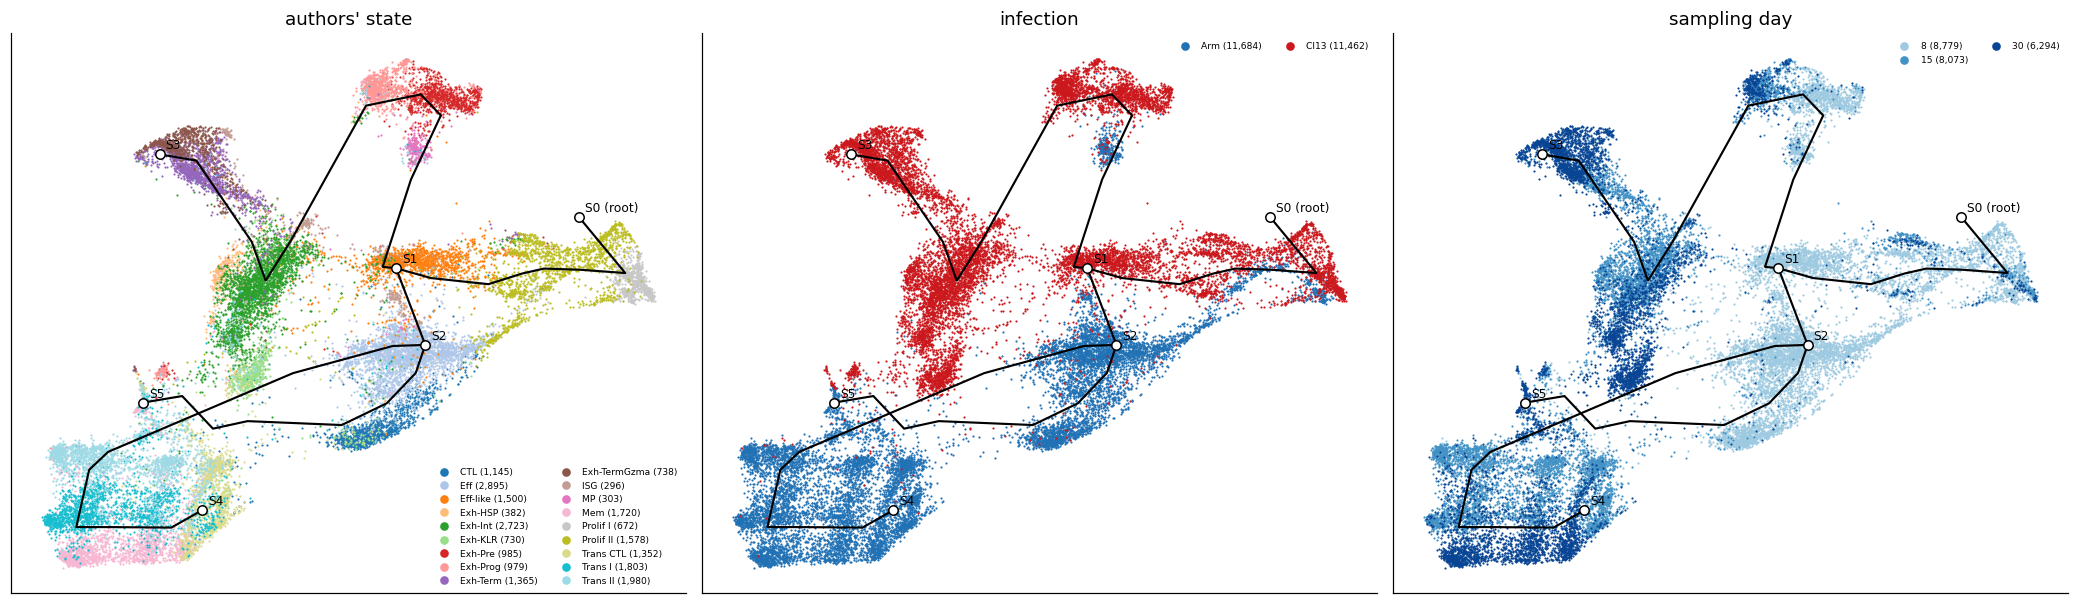

In [2]:
s = meta["target_score"]
display(Markdown("graph space `{}`, config `{}`  \nArm / Cl13 split F1 **{:.2f}**, state order Arm {:.2f} / Cl13 {:.2f}, day order Arm {:.2f} / Cl13 {:.2f}, "
                 "root mostly {}, Arm arm ends in **{}**, Cl13 arm ends in **{}**, {} leaves, {:,} cells".format(
    meta["graph_space"], meta["config"], s["split_f1"], s["order_arm"], s["order_cl13"], s["day_arm"], s["day_cl13"],
    s["root_top"], s["arm_end"], s["cl13_end"], s["n_leaves"], meta["n_cells"])))
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, column, colors, title in zip(axes, ["ClusterNames", "infection", "day"], [STATE_COL, INF_COL, DAY_COL], ["authors' state", "infection", "sampling day"]):
    scatter(ax, cell[column].astype(str), colors, title)
fig.tight_layout(); plt.show()

## The two Focal branches

Cells by the path they are on: the trunk shared by both branches (S0 -> S1), the rest of the root -> Mem path (S1 -> S2 -> S4), the rest of the root -> Exh-Term path (S1 -> S3), and the S2 -> S5 arm that neither branch uses.

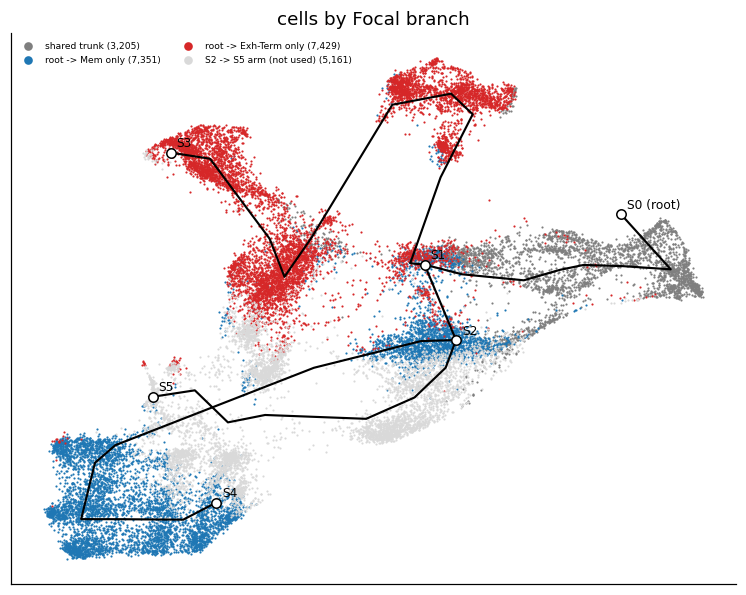

infection,Arm,Cl13,All
part,,,
S2 -> S5 arm (not used),3766,1395,5161
root -> Exh-Term only,450,6979,7429
root -> Mem only,6741,610,7351
shared trunk,727,2478,3205
All,11684,11462,23146


In [4]:
mem, exh = cell["on_path_S4"], cell["on_path_S3"]
part = np.select([mem & exh, mem, exh], ["shared trunk", "root -> Mem only", "root -> Exh-Term only"], "S2 -> S5 arm (not used)")
PART_COL = {"shared trunk": "#7f7f7f", "root -> Mem only": "#1f77b4", "root -> Exh-Term only": "#d62728", "S2 -> S5 arm (not used)": "#d9d9d9"}
fig, ax = plt.subplots(figsize=(8.5, 6.5))
scatter(ax, pd.Series(part, index=cell.index), PART_COL, "cells by Focal branch"); plt.show()
display(pd.crosstab(pd.Series(part, index=cell.index, name="part"), cell["infection"], margins=True))

## The Dictys windows

Every window is a set of about 1,040 neighbouring cells along the tree (`focal/G/dictys/tmp_dynamic/SubsetN/names_rna.txt`); neighbouring windows share 75 % of their cells. Below: each window at the mean position of its cells, numbered by its position along its branch (windows on the shared trunk carry the same number on both branches).

**116** windows in total, 1,042-1,042 cells each; root -> Mem **52**, root -> Exh-Term **52**, shared **15**, on neither branch (S2 -> S5 arm) **27**

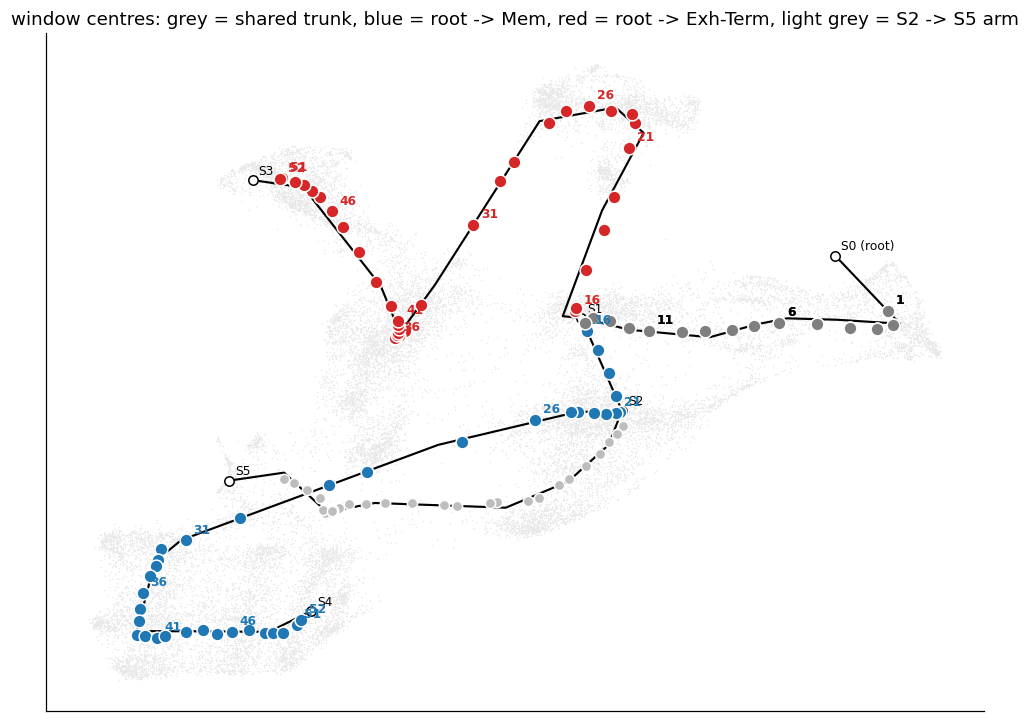

In [5]:
W = FOCAL / "G/dictys/tmp_dynamic"
win = {b: pd.read_csv(FOCAL / "analysis/G" / b / "window_path.csv") for b in BRANCHES}
names = {w: [l.strip() for l in open(W / w / "names_rna.txt") if l.strip()] for w in sorted(p.name for p in W.glob("Subset*"))}
on = {b: set(win[b]["subset"]) for b in BRANCHES}
display(Markdown("**{}** windows in total, {:,}-{:,} cells each; root -> Mem **{}**, root -> Exh-Term **{}**, shared **{}**, on neither branch (S2 -> S5 arm) **{}**".format(
    len(names), min(map(len, names.values())), max(map(len, names.values())), len(on["Mem"]), len(on["Exh"]), len(on["Mem"] & on["Exh"]),
    len(set(names) - on["Mem"] - on["Exh"]))))
fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(cell.x, cell.y, s=1, color="#e8e8e8", linewidths=0, rasterized=True)
draw_tree(ax)
for w in set(names) - on["Mem"] - on["Exh"]:
    ax.scatter(*cell.loc[names[w], ["x", "y"]].mean(), s=45, color="#bdbdbd", edgecolor="white", zorder=6)
for b, (title, _, col) in BRANCHES.items():
    for _, r in win[b].iterrows():
        shared = r.subset in on["Mem"] and r.subset in on["Exh"]
        xy = cell.loc[names[r.subset], ["x", "y"]].mean()
        ax.scatter(*xy, s=70, color="#7f7f7f" if shared else col, edgecolor="white", zorder=7)
        if r.path_position % 5 == 1 or r.path_position == len(win[b]):
            ax.annotate(str(r.path_position), xy, xytext=(5, 5), textcoords="offset points", fontsize=8, color="black" if shared else col, weight="bold", zorder=8)
ax.set_title("window centres: grey = shared trunk, blue = root -> Mem, red = root -> Exh-Term, light grey = S2 -> S5 arm")
plt.show()

## Along each branch: composition, total Focal force and composition speed

Top: the authors' state composition of every window (bars), the total Focal force (black; sum of |force| over the 20,000 strongest TF -> target links, log2 CPM TF expression) and the composition speed (red dashed; % points of composition changing per window), both smoothed over 1.5 windows; red triangles = speed minima = attractor states. Bottom: the samples in each window.

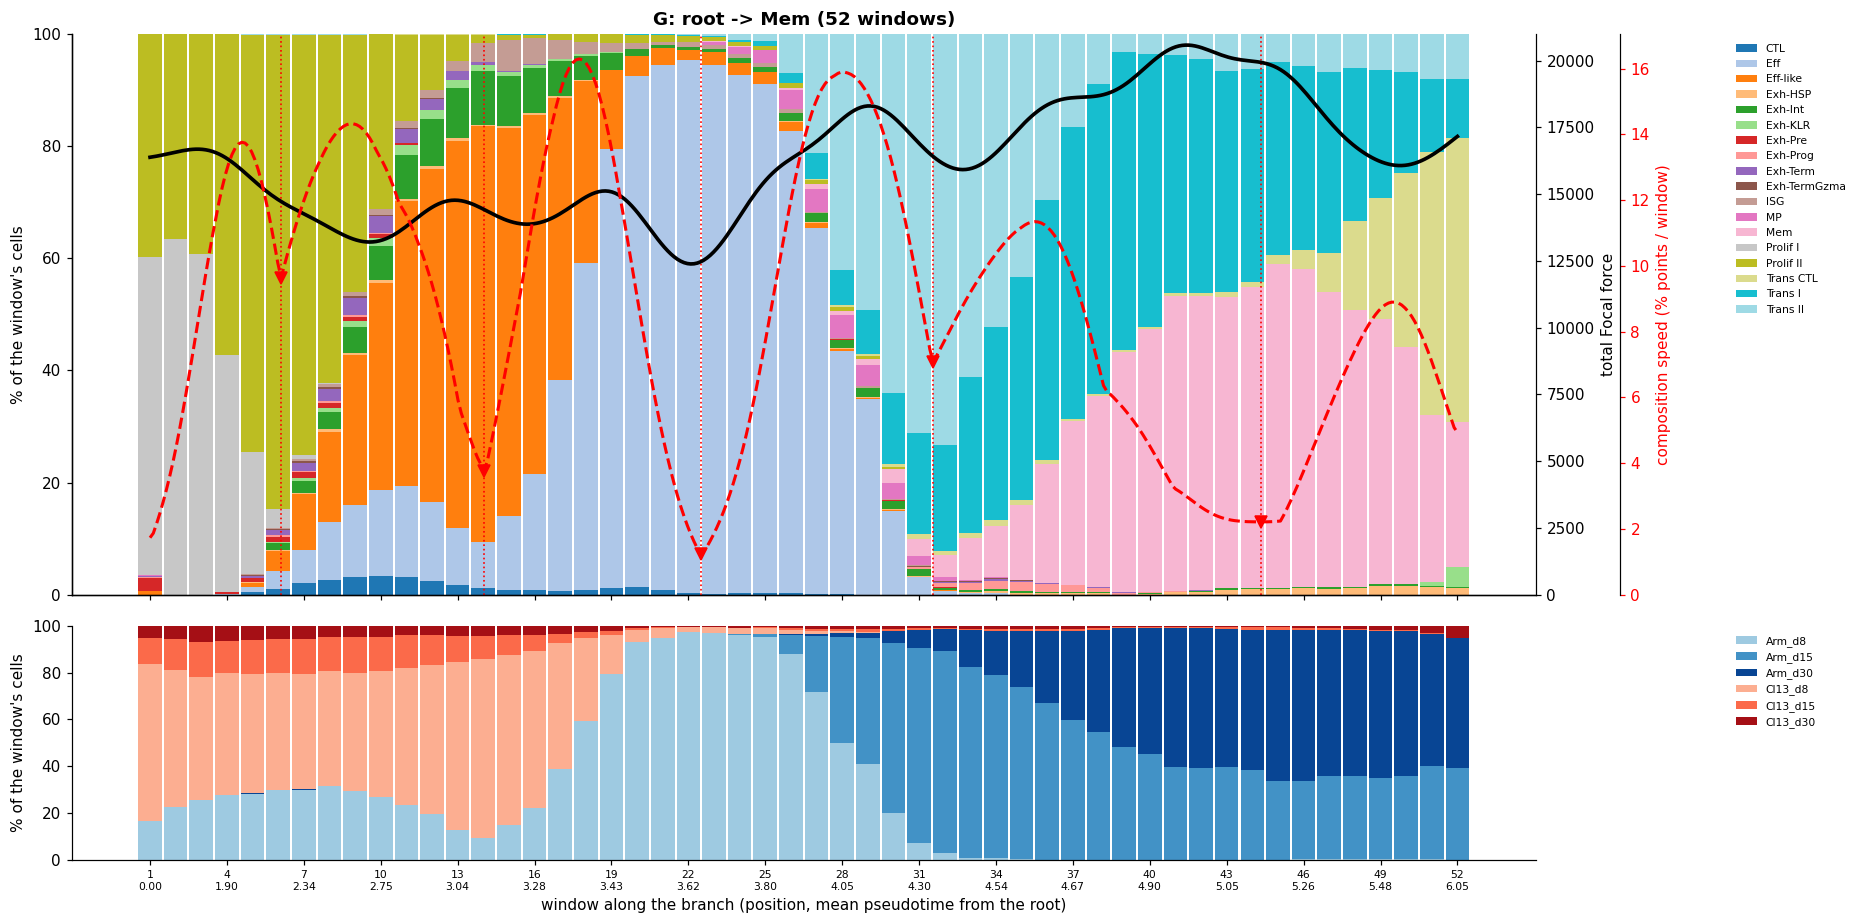

,attractor,window,dominant_state,share_%
0,1,6.1,Prolif II,71.0
1,2,14.0,Eff-like,67.0
2,3,22.5,Eff,93.0
3,4,31.5,Trans II,65.0
4,5,44.3,Mem,54.0


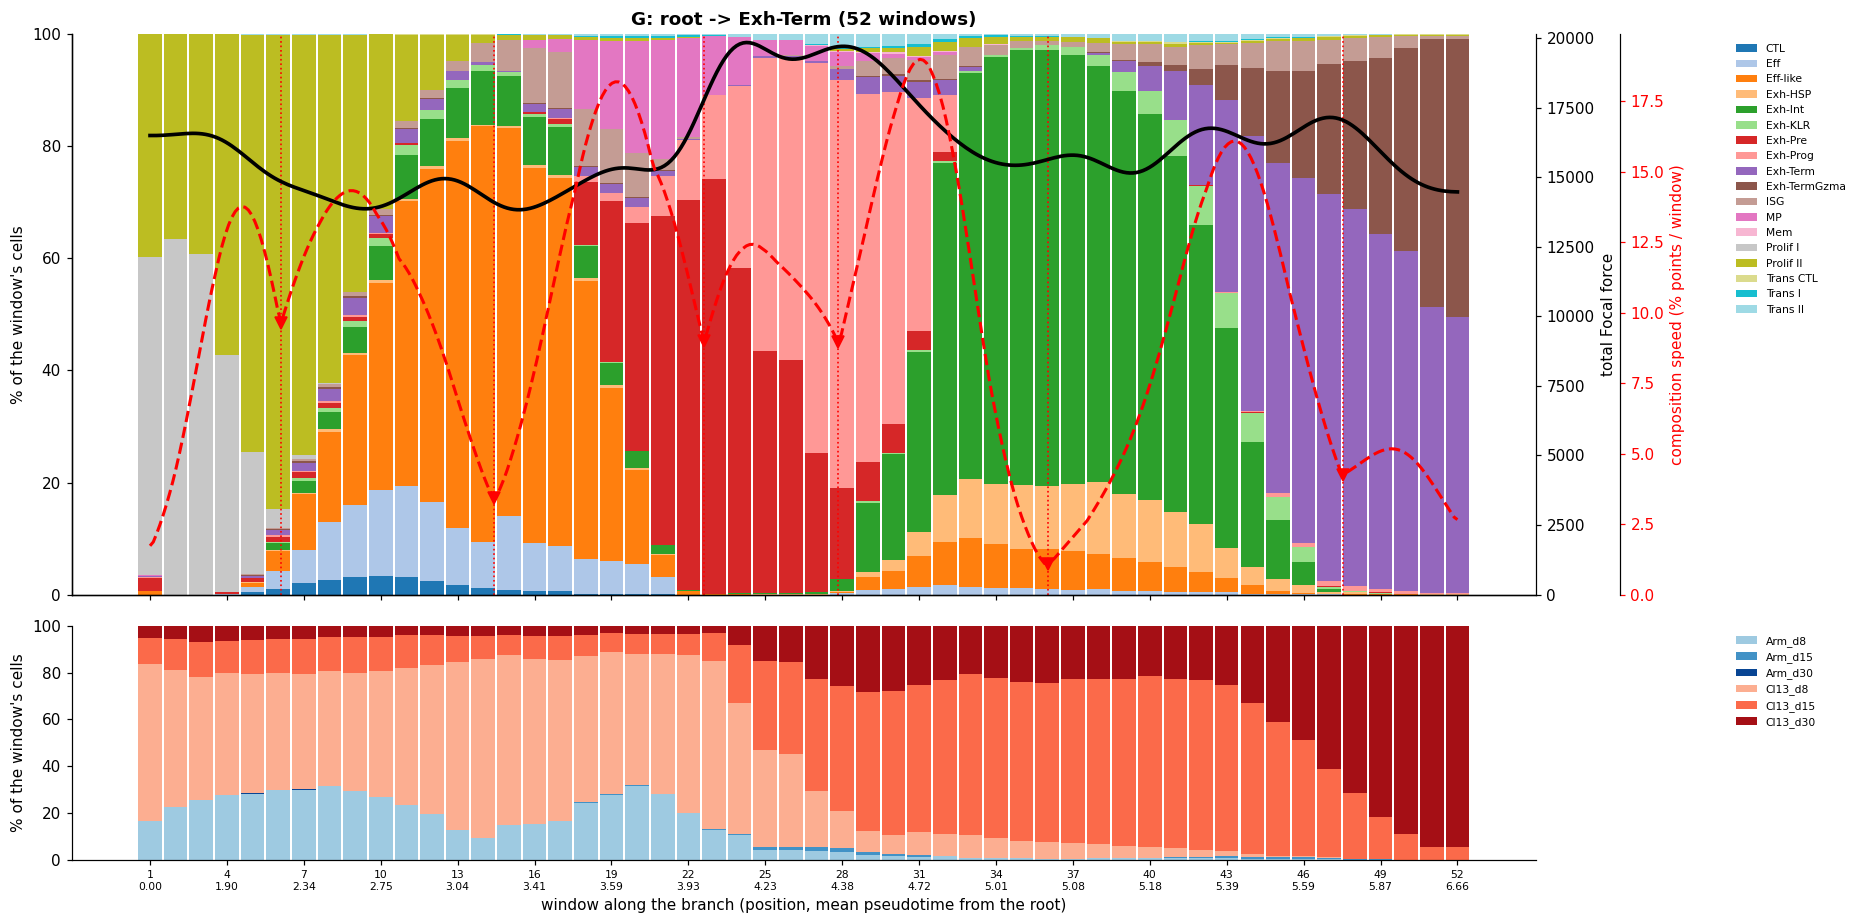

,attractor,window,dominant_state,share_%
0,1,6.1,Prolif II,71.0
1,2,14.4,Eff-like,68.0
2,3,22.6,Exh-Pre,62.0
3,4,27.8,Exh-Prog,64.0
4,5,36.0,Exh-Int,76.0
5,6,47.5,Exh-Term,65.0


In [6]:
for b, (title, _, col) in BRANCHES.items():
    comp = pd.read_csv(FOCAL / "analysis/G" / b / "composition.csv")
    cur = pd.read_csv(FOCAL / "analysis/G" / b / "attractor_curves.csv")
    order = win[b]["subset"].tolist(); x = np.arange(1, len(order) + 1)
    st = comp.pivot_table(index="subset", columns="state", values="percent", fill_value=0).reindex(order)
    st = st[[s for s in STATE_COL if s in st.columns]]
    sm = pd.DataFrame([cell.loc[names[w], "sampleID"].value_counts(normalize=True) * 100 for w in order], index=order).fillna(0)
    sm = sm[[s for s in SAMPLE_COL if s in sm.columns]]
    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(17, 8.5), sharex=True, gridspec_kw={"height_ratios": [2.4, 1]})
    for d, colors, a in [(st, STATE_COL, ax), (sm, SAMPLE_COL, ax2)]:
        bottom = np.zeros(len(d))
        for c in d.columns:
            a.bar(x, d[c], bottom=bottom, width=0.92, color=colors[c], linewidth=0, label=c); bottom += d[c].to_numpy()
        a.set(ylim=(0, 100), ylabel="% of the window's cells")
    ax.legend(frameon=False, fontsize=7, bbox_to_anchor=(1.13, 1), loc="upper left"); ax2.legend(frameon=False, fontsize=7, bbox_to_anchor=(1.13, 1), loc="upper left")
    af = ax.twinx(); af.plot(cur.window_position, cur.force_abs, color="black", lw=2.4); af.set_ylabel("total Focal force"); af.set_ylim(bottom=0); af.spines["right"].set_visible(True)
    av = ax.twinx(); av.spines["right"].set_position(("outward", 55)); av.spines["right"].set_visible(True)
    av.plot(cur.window_position, cur.speed, color="red", lw=2, ls="--"); av.set_ylabel("composition speed (% points / window)", color="red"); av.tick_params(axis="y", colors="red"); av.set_ylim(bottom=0)
    mins = argrelmin(cur.speed.to_numpy())[0]
    av.plot(cur.window_position.iloc[mins], cur.speed.iloc[mins], "v", color="red", ms=8)
    for m in cur.window_position.iloc[mins]:
        ax.axvline(m, color="red", ls=":", lw=1.1)
    pt = win[b].set_index("subset").loc[order, "mean_pseudotime"]
    ax2.set_xticks(x[::3]); ax2.set_xticklabels(["{}\n{:.2f}".format(i, p) for i, p in zip(x[::3], pt.iloc[::3])], fontsize=7)
    ax2.set_xlabel("window along the branch (position, mean pseudotime from the root)")
    ax.set_title("G: {} ({} windows)".format(title, len(order)), weight="bold")
    fig.tight_layout(); plt.show()
    scols = [c for c in cur.columns if c.startswith("smoothed_pct_")]
    at = cur.iloc[mins]
    display(pd.DataFrame({"attractor": range(1, len(at) + 1), "window": at["window_position"].round(1).to_numpy(),
                          "dominant_state": [c.replace("smoothed_pct_", "") for c in at[scols].astype(float).idxmax(axis=1)],
                          "share_%": at[scols].astype(float).max(axis=1).round(0).to_numpy()}))